# Sky Calibration: Appliaction part

## Overview

Application part of the sky calibraton derives the calibrated spectra, i.e. contribution from the atmosphere is subtracted and physical intensity scale is given, using the calibration solution generated by the calibration part of the sky calibration process (see [this notebook](./sdcal_calibration.ipynb) for the detail about the calibration part. Calibration solution in this case is an off-source spectral data averaged over time for each subscan with OFF_SOURCE intent. The off-source data are the reference data that contains all the contributions except the one from target source. Therefore, we can extract the emission from the source by subtracting off-source data from on-source data. In addition, off-source data, together with the system temperature, $T_{\rm sys}$, are can be used to give physical intensity scale to the calibrated data. In summary, calibrated spectrum with physical intensity scale can be obtained by,

$$
    T_{\rm a}^{\ast} = T_{\rm sys} \frac{({\rm ON} - {\rm OFF})}{{\rm OFF}},
$$

where $T_{\rm a}^{\ast}$ is calibrated spectrum, $T_{\rm sys}$ is the system temperature, ${\rm ON}$ and ${\rm OFF}$ are raw spectra for on-source and off-source positions, respectively. The above computation will be done when sky calibration solution is applied together with $T_{\rm sys}$ solution. The application part of the sky calibration is responsible for the computation of

$$
    \frac{{\rm ON} - {\rm OFF}}{{\rm OFF}}.
$$

Similar to the $T_{\rm sys}$ calibration, explained in [this notebook](./tsyscal.ipynb), atmospheric scans, on-source scans, and off-source scans are executed sequentially so that they are separated in time. Therefore, we need to interporate calibration solutions into the time for on-source scans. The interpolation scheme is somewhat arbitrary. But typically it will be linear or spline. If there is only one solution, only nearest will be applicable.

Data weight need to be updated according to the quality of the off-source data. 


## Input Data

* Calibration solution (time-averaged off-source data)
* On-source spectral data, flag, and weight values associated with them
* Associated metadata, timestamp, exposure time, antenna ID, spectral window ID, field ID

## Output Data

* "Calibrated" data, which is supposed to contain only the emission from the target (although that is often not true)
* Updated flag
* Updated weight value

## Algorithm

### Interpolation of calibration solution (off-source data) to on-source data

Just like [tsys calibration](./tsyscal.ipynb), off-source data need to be interporated to on-source time. Suppose we have on-source data at time, $t$, which is bracketed by two off-source subscans at $t^{\rm OFF}_1$ and $t^{\rm OFF}_2$. If $t^{\rm OFF}_1 < t < t^{\rm OFF}_2$, then, in the case of linear interpolation, interpolated value, ${\rm OFF}(t)$, is expressed as,

$$
    {\rm OFF}(t) = \frac{{\rm OFF}(t^{\rm OFF}_2) - {\rm OFF}(t^{\rm OFF}_1)}{(t^{\rm OFF}_2 - t^{\rm OFF}_1)} (t - t^{\rm OFF}_1) + {\rm OFF}(t^{\rm OFF}_1). 
$$

CASA offers four interpolation options: `'nearest'`, `'linear'`, `'cubic'`, and `'spline'`.


### Application

The application operation is written as follows.

$$
    {\rm CAL}(t) = \frac{{\rm ON}(t) - {\rm OFF}(t)}{{\rm OFF}(t)},
$$

where ${\rm CAL}(t)$ and ${\rm ON}(t)$ are calibrated and raw on-source data at time $t$, respectively. ${\rm OFF}(t)$ is the off-source data interporated to the time $t$.


### Flagging

Flag information in the calibration solution should be propagated to the on-source data. Basically, on-source data that are calibrated by flagged calibration solution will be flagged. In CASA MS/Caltable convention, flag is represented as boolean value. If flag is `False`, it means that the data is valid. On the other hand, `True` means that associated data have any problem so they are invalid. Since calibration solution is interpolated in time, the flag information must also be "interpolated". In addition to the interpolation explained below, flag associated with zero value must also be set to `True` although this is not implemented in the current CASA 6 code.

#### Nearest interpolation

"Interpolation" of the flag information is obvious. Flags in calibration solution is directly propagated to the on-source data. Then, flags are updated by "channel-wise OR". 

$$
    {\rm Flag}_{\rm CAL} = {\rm Flag}_{\rm ON} \lor {\rm Flag}_{\rm OFF},
$$

where ${\rm Flag}$ is the flag information associated with each data, $\lor$ is the operator for "logical OR". The above formula means that the flag for calibrated data will be `True` (invalid) if flags for either on-source or off-source data (or both) are `True`.

#### Other interpolations (linear, cubic, spline)

For other interpolations, multiple off-source data are used to calibrate the on-source data because of the interpolation. In the current implementation, only flags for neighboring off-source data in time are used to update the flag for on-source data. That is accurate treatment for linear interpolation, but might need improvement for cubic and spline interpolations. The update formula will be similar to the nearest case, but there are two off-source flags.

$$
    {\rm Flag}_{\rm CAL} = {\rm Flag}_{\rm ON} \lor {\rm Flag}_{\rm OFF1} \lor {\rm Flag}_{\rm OFF2},
$$

where ${\rm Flag}_{\rm OFF1}$ and ${\rm Flag}_{\rm OFF2}$ indicate the flags for off-source data that brackets the on-source data in time, corresponding to the flags for ${\rm OFF}(t^{\rm OFF}_1)$ and ${\rm OFF}(t^{\rm OFF}_2)$ in the above formula in Interpolation section, respectively.


### Weight update

Attachments in [CAS-6994](https://open-jira.nrao.edu/browse/CAS-6994) describes how data weights have to be updated. The weights are updated using the effective exposure time, $\tau$, of both on-source and off-source data. The formula depends on the interpolation option. 

#### Nearest interpolation

Weight, $w$, is an inverse square of estimated rms noise of the data, $\sigma$. The formula below shows how weight for the calibrated data are calbulated from on-source and off-source data.

$$
    \begin{align}
        \sigma_{\rm CAL} &= \sqrt{\sigma_{\rm ON}^2 + \sigma_{\rm OFF}^2} \\
                         &= \sigma_{\rm ON} \sqrt{1 + \frac{\tau_{\rm ON}}{\tau_{\rm OFF}}}, \\
        w_{\rm CAL}      &= \frac{1}{\sigma_{\rm CAL}^2} \\
                         &= \frac{1}{\sigma_{\rm ON}^2} \frac{\tau_{\rm OFF}}{\tau_{\rm ON} + \tau_{\rm OFF}} \\
                         &= w_{\rm ON} \frac{\tau_{\rm OFF}}{\tau_{\rm ON} + \tau_{\rm OFF}}.
    \end{align}
$$

where $w_{\rm CAL}$ and $w_{\rm ON}$ are the weights for calibrated and on-source data, respectively. Also, $\sigma_{\rm CAL}$, $\sigma_{\rm ON}$, and $\sigma_{\rm OFF}$ are the estimated rms noises for calibrated, on-source, and off-source data, respectively. Finally, $\tau_{\rm ON}$ and $\tau_{\rm OFF}$ are exposure times for on-source and off-source data. Note that the off-source data is the time-average of the consecutive integrations in each off-source subscan. According to the formula, $\tau_{\rm OFF}$ must be significantly longer than $\tau_{\rm ON}$ not to degrade the weight for the calibrated data compared with the on-source weight. Balance of exposure time between on-source and off-source data is taken into account when observation is designed.

#### Linear interpolation

For linear interpolation, we should take into account the weights for two off-source data. That is implemented as follows.

$$
    \begin{align}
        \sigma_{\rm OFF}^2 &= \frac{{(t^{\rm OFF}_2 - t)^2 \sigma_{\rm OFF1}^2 + (t - t^{\rm OFF}_1)^2 \sigma_{\rm OFF2}^2}}{(t^{\rm OFF}_2 - t^{\rm OFF}_1)^2} \\
        \sigma_{\rm CAL} &= \sqrt{\sigma_{\rm ON}^2 + \sigma_{\rm OFF}^2} \\
                         &= \sigma_{\rm ON} \sqrt{1 + \frac{\tau_{\rm ON}}{(t^{\rm OFF}_2 - t^{\rm OFF}_1)^2}\left(\frac{(t^{\rm OFF}_2 - t)^2}{\tau_{\rm OFF1}} + \frac{(t - t^{\rm OFF}_1)^2}{\tau_{\rm OFF2}}\right)} \\
        w_{\rm CAL} &= \frac{1}{\sigma_{\rm CAL}^2} \\
                    &= w_{\rm ON} \left[1 + \frac{\tau_{\rm ON}}{(t^{\rm OFF}_2 - t^{\rm OFF}_1)^2}\left(\frac{(t^{\rm OFF}_2 - t)^2}{\tau_{\rm OFF1}} + \frac{(t - t^{\rm OFF}_1)^2}{\tau_{\rm OFF2}}\right)\right]^{-1}
    \end{align}
$$

Here, $\sigma_{\rm OFF}$ is nominal rms estimate derived from two off-source data.


## Reference Python Implementation

### Input Data

Here input data are grouped as dict for each intent. There can be any number of dict objects corresponding to each combination of metadata, e.g., antenna, spw, and field.

Text(0.5, 1.0, 'INPUT DATA (dots: ON source, circles: OFF source)')

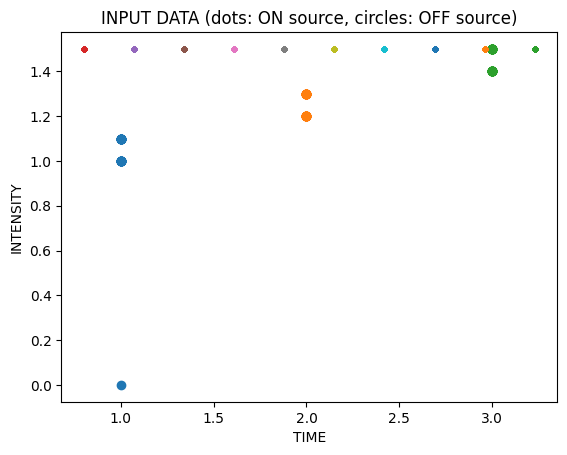

In [1]:
import numpy as np
import matplotlib.pyplot as plt

npol = 2
nchan = 16

# OFF-source data with timestamp and exposure 
nrow_off = 3
off = np.zeros((npol, nchan, nrow_off), dtype=float)
for irow in range(nrow_off):
    for ipol in range(npol):
        off[ipol, :, irow] = 0.1 * (irow * npol + ipol) + 1
off[0, 5, 0] = 0.0  # accidentally, some off-source data is zero
flag_off = np.zeros_like(off, dtype=bool)
flag_off[1, 14:, 2] = True  # flag a part of the last off-source data
time_off = np.arange(1, nrow_off + 1, dtype=float)
exposure_off = np.array([1, 10, 100], dtype=float)

# ON-source data with timestamp and exposure
nrow_on = 10
on = np.zeros((npol, nchan, nrow_on), dtype=float) + 1.5
flag_on = np.zeros_like(on, dtype=bool)
flag_on[:, :1, :] = True  # edge channels are flagged
time_on = np.arange(0.8, 3.5, 0.27, dtype=float)
exposure_on = np.zeros(nrow_on, dtype=float) + 1

# Weight for ON-source
weight_on = np.zeros_like(on, dtype=float) + 1.0

# For simplicity, assume that the data contains only one spw, one field, and one antenna
spw_id = 0
field_id = 0
antenna_id = 0

# Structured OFF-source data
ps_off = [{
  'header': {
      'antenna_id': antenna_id,
      'spw_id': spw_id,
      'field_id': field_id,
  },
  'data': {
      'time': time_off,
      'exposure': exposure_off,
      'spectra': off,
      'flag': flag_off,
  }
}]

# Structured ON-source data
ps_on = [{
  'header': {
      'antenna_id': antenna_id,
      'spw_id': spw_id,
      'field_id': field_id,
  },
  'data': {
      'time': time_on,
      'exposure': exposure_on,
      'spectra': on,
      'flag': flag_on,
      'weight': weight_on,
  }
}]

def get_selector(antenna_id, spw_id, field_id):
    return lambda x: x['header']['antenna_id'] == antenna_id and x['header']['spw_id'] == spw_id and x['header']['field_id'] == field_id

selector = get_selector(antenna_id, spw_id, field_id)
it = zip(filter(selector, ps_off), filter(selector, ps_on))
chunk_off, chunk_on = next(it)

for irow in range(nrow_off):
    y = chunk_off['data']['spectra'][:, :, irow].flatten()
    x = np.zeros_like(y, dtype=float) + chunk_off['data']['time'][irow]
    plt.plot(x, y, 'o')
for irow in range(nrow_on):
    y = chunk_on['data']['spectra'][:, :, irow].flatten()
    x = np.zeros_like(y, dtype=float) + chunk_on['data']['time'][irow]
    plt.plot(x, y, '.')
plt.xlabel('TIME')
plt.ylabel('INTENSITY')
plt.title('INPUT DATA (dots: ON source, circles: OFF source)')

### Application

Here off-source data are interpolated to the time for each on-source data, and then applied. In this example, linear interpolation is used. Flag data are propagated accordingly. 

Text(0.5, 1.0, 'CALIBRATED DATA (dots: raw, circles: calibrated)')

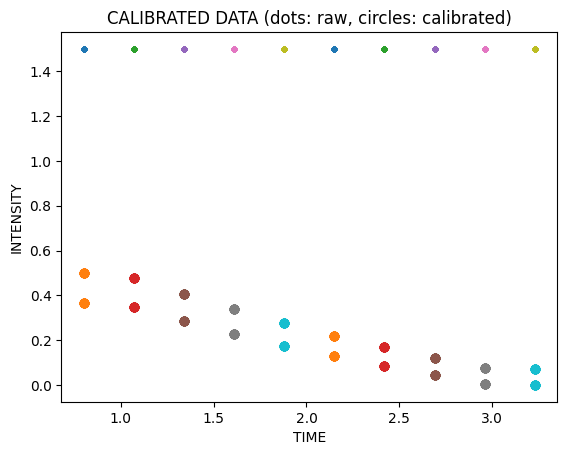

In [2]:
import itertools

import numpy as np

off_source_time = chunk_off['data']['time']
on_source_time = chunk_on['data']['time']

# sort off-source and on-source times jointly
sorted_indices = np.argsort(np.concatenate((off_source_time, on_source_time)))
# print(sorted_indices)
off_source_time_indices = [np.where(sorted_indices == i)[0][0] for i in range(nrow_off)]  
index_offset = nrow_off
# print(off_source_time_indices)
# functions to identify the list of on-source times that are outside of, or in between the off-source times
def on_source_time_indices_before_first_off():
    return sorted_indices[:off_source_time_indices[0]] - index_offset

def on_source_time_indices_after_final_off():
    return sorted_indices[off_source_time_indices[-1] + 1:] - index_offset

def on_source_time_indices_in_between(off_idx1, off_idx2):
    return sorted_indices[list(range(off_idx1 + 1, off_idx2))] - index_offset

cal = np.empty_like(chunk_on['data']['spectra'], dtype=float)
flag_cal = np.empty_like(chunk_on['data']['flag'], dtype=bool)
for ipol in range(npol):
    for ichan in range(nchan):
        # off-source spectra
        yp = chunk_off['data']['spectra'][ipol, ichan, :].copy()
        _flag_off = chunk_off['data']['flag'][ipol, ichan, :]
        # additional flag if off-source data is zero
        _effective_flag_off = np.logical_or(_flag_off, yp == 0.0)
        
        # application of calibration solution
        # linear interpolation (fallback to nearest when linear cannot be applied)
        # set tiny value to suppress zero-division warning
        yp[yp == 0.0] = np.finfo(float).tiny
        _off = np.interp(on_source_time, off_source_time, yp)

        # (ON - OFF) / OFF
        _on = chunk_on['data']['spectra'][ipol, ichan, :]
        cal[ipol, ichan, :] = (_on - _off) / _off

        # update flag
        _flag_on = chunk_on['data']['flag'][ipol, ichan, :]
        _on_source_indices = on_source_time_indices_before_first_off()
        # fallback to nearest interpolation, taking logical OR with one off-source flag
        flag_cal[ipol, ichan, _on_source_indices] = np.logical_or(_flag_on[_on_source_indices], _effective_flag_off[0])
        for i, j in itertools.pairwise(off_source_time_indices):
            _on_source_indices = on_source_time_indices_in_between(i, j)
            _off_source_index1 = sorted_indices[i]
            _off_source_index2 = sorted_indices[j]
            # linear interpolation, taking logical OR with two off-source flags
            flag_cal[ipol, ichan, _on_source_indices] = np.logical_or(
                _flag_on[_on_source_indices],
                np.logical_or(_effective_flag_off[_off_source_index1], _effective_flag_off[_off_source_index2])
            )
        # fallback to nearest interpolation, taking logical OR with one off-source flag
        _on_source_indices = on_source_time_indices_after_final_off()
        flag_cal[ipol, ichan, _on_source_indices] = np.logical_or(_flag_on[_on_source_indices], _effective_flag_off[-1])        

corrected = {
    'time': chunk_on['data']['time'],
    'exposure': chunk_on['data']['exposure'],
    'spectra': cal,
    'flag': flag_cal,
    'weight': None,  # will be filled in the subsequent cell
}
chunk_on['corrected_data'] = corrected

for irow in range(nrow_on):
    y = chunk_on['data']['spectra'][:, :, irow].flatten()
    x = np.zeros_like(y, dtype=float) + chunk_on['data']['time'][irow]
    plt.plot(x, y, '.')
    y = chunk_on['corrected_data']['spectra'][:, :, irow].flatten()
    m = chunk_on['corrected_data']['flag'][:, :, irow].flatten()
    ym = np.ma.masked_array(y, m)
    plt.plot(x, ym, 'o')
plt.xlabel('TIME')
plt.ylabel('INTENSITY')
plt.title('CALIBRATED DATA (dots: raw, circles: calibrated)')


### Weight update

Weights are updated using the timestamp and exposure time for on-source and off-source data.

Although initial weight values for on-source data are constant, update weights increases with time. That is because exposure times for off-source data increases at later time. Generated plot show weight values as well as exposure time.

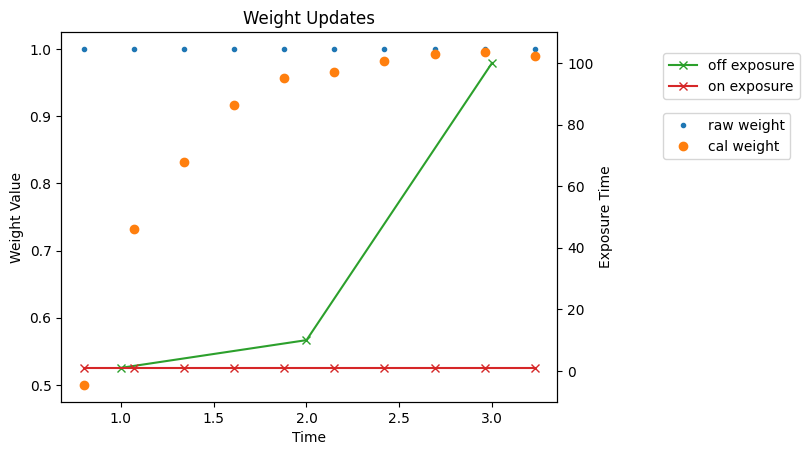

In [3]:
off_source_time = chunk_off['data']['time']
on_source_time = chunk_on['data']['time']
exposure_off = chunk_off['data']['exposure']
exposure_on = chunk_on['data']['exposure']
weight_on = chunk_on['data']['weight']

weight_cal = np.empty_like(weight_on, dtype=float)

_on_source_indices = on_source_time_indices_before_first_off()
weight_cal[:, :, _on_source_indices] = weight_on[:, :, _on_source_indices] * exposure_off[0] / (exposure_off[0] + exposure_on[_on_source_indices])

for i, j in itertools.pairwise(off_source_time_indices):
    _on_source_indices = on_source_time_indices_in_between(i, j)
    _off_source_index1 = sorted_indices[i]
    _off_source_index2 = sorted_indices[j]
    dt_off = off_source_time[_off_source_index2] - off_source_time[_off_source_index1]
    dt_on1 = on_source_time[_on_source_indices] - off_source_time[_off_source_index1]
    dt_on2 = off_source_time[_off_source_index2] - on_source_time[_on_source_indices]
    denominator = np.sqrt(1 + exposure_on[_on_source_indices] / np.square(dt_off) 
                          * (np.square(dt_on2) / exposure_off[_off_source_index1] + np.square(dt_on1) / exposure_off[_off_source_index2]))
    weight_cal[:, :, _on_source_indices] = weight_on[:, :, _on_source_indices] / denominator

_on_source_indices = on_source_time_indices_after_final_off()
weight_cal[:, :, _on_source_indices] = weight_on[:, :, _on_source_indices] * exposure_off[-1] / (exposure_off[-1] + exposure_on[_on_source_indices])

# set updated weight to corrected_data
chunk_on['corrected_data']['weight'] = weight_cal

colors = (c['color'] for c in plt.rcParams['axes.prop_cycle'])
plt.plot(on_source_time, weight_on[0, 0, :], '.', color=next(colors), label='raw weight')
plt.plot(on_source_time, weight_cal[0, 0, :], 'o', color=next(colors), label='cal weight')
plt.title('Weight Updates')
plt.xlabel('Time')
plt.ylabel('Weight Value')
plt.legend(bbox_to_anchor=(1.2, 0.8), loc='upper left')
a = plt.twinx()
plt.plot(off_source_time, exposure_off, 'x-', color=next(colors), label='off exposure')
plt.plot(on_source_time, exposure_on, 'x-', color=next(colors), label='on exposure')
plt.ylabel('Exposure Time')
plt.ylim((-10, 110))
plt.legend(bbox_to_anchor=(1.2, 0.8), loc='lower left')

# chunk_on['corrected_data']

## Note for Developers

For those who want to dig into detail about CASA 6 implementation, here is an information on the code that actually implements the above logic. Class and method names with the rough call-graph are shown.

### Application

```
applycal (task_applycal.py)
-> calibrater::correct (calibrater_cmpt.cc)
-> Calibrater::correct2 (Calibrater.cc)
-> VisEquation::correct2 (VisEquation.cc)
-> VisCal::correct2 (VisCal.cc)
-> SingleDishSkyCal::applyCal2 (SingleDishSkyCal.cc)
-> SkyCal::apply (SkyCal.h)
```

### Flagging & Interpolation

```
applycal (task_applycal.py)
-> calibrater::correct (calibrater_cmpt.cc)
-> Calibrater::correct2 (Calibrater.cc)
-> VisEquation::correct2 (VisEquation.cc)
-> VisCal::correct2 (VisCal.cc)
-> VisCal::syncCal2
-> VisCal::syncCal
-> VisCal::syncPar
-> SolvableVisCal::calcPar
-> CTPatchedInterp::interpolate
-> CTTimeInterp1::interpolate
```

### Weight Updates

```
applycal (task_applycal.py)
-> calibrater::correct (calibrater_cmpt.cc)
-> Calibrater::correct2 (Calibrater.cc)
-> VisEquation::correct2 (VisEquation.cc)
-> VisCal::correct2 (VisCal.cc)
-> VisCal::syncCal2
-> VisCal::syncCal
-> SingleDishSkyCal::syncCalMat (SingleDishSkyCal.cc)
-> SingleDishSkyCal::syncWtScale
-> SingleDishSkyCal::calcWtScale
-> NearestWeightScalingScheme::InterpolateScale
or LinearWeightScalingScheme::InterpolateScale (SingleDishSkyCal.cc)
```

## Reference

1. [CAS-6994 MS transition: update weight in sky calibration](https://open-jira.nrao.edu/browse/CAS-6994)